## Streaming
- This module will dive into human-in-the-loop, which builds on memory and allows users to interact directly with graphs in various ways.
- To set the stage for human-in-the-loop, we'll first dive into streaming, which provides several ways to visualize graph output (e.g., node state or chat model tokens) over the course of execution.

## Streaming

LangGraph is built with [first class support for streaming](https://docs.langchain.com/oss/python/langgraph/streaming)

In [1]:
from IPython.display import Image, display
from typing import Literal

from langchain_ollama import ChatOllama
from langchain_core.messages import SystemMessage, HumanMessage, RemoveMessage
from langchain_core.runnables import RunnableConfig

from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, START, END
from langgraph.graph import MessagesState

In [2]:
model = ChatOllama(model= "qwen2.5:7b")

In [3]:

class State(MessagesState):
    summary: str

In [4]:
def call_model(state:State, config:RunnableConfig):
    summary = state.get("summary", "")

    if summary:
        system_message = f"Summary of conversation earlier: {summary}"
        messages = [SystemMessage(content=system_message)] + state["messages"]
    
    else:
        messages = state["messages"]
    
    response = model.invoke(messages)

    return {
        "messages": response
    }




In [5]:
def summarize_conversation(state:State):

    summary = state.get("summary", "")

    if summary:
        summary_message =  (
            f"This is summary of the conversation to date: {summary}\n\n"
            "Extend the summary by taking into account the new messages above:"
        )
    
    else:
        summary_message = "Create a summary of the conversation above:"
    
    messages = state["messages"] + [HumanMessage(content=summary_message)]
    response = model.invoke(messages)

    delete_messages = [RemoveMessage(id=m.id) for m in state["messages"][:-2]]
    return {"summary": response.content, "messages": delete_messages}





In [6]:
# Determine whether to end or summarize the conversation
def should_continue(state: State)-> Literal ["summarize_conversation",END]:
    
    """Return the next node to execute."""
    
    messages = state["messages"]
    
    # If there are more than six messages, then we summarize the conversation
    if len(messages) > 6:
        return "summarize_conversation"
    
    # Otherwise we can just end
    return END

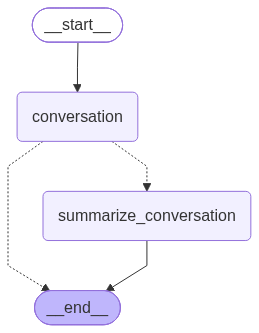

In [7]:
# Define a new graph
workflow = StateGraph(State)
workflow.add_node("conversation", call_model)
workflow.add_node(summarize_conversation)

# Set the entrypoint as conversation
workflow.add_edge(START, "conversation")
workflow.add_conditional_edges("conversation", should_continue)
workflow.add_edge("summarize_conversation", END)

# Compile
memory = MemorySaver()
graph = workflow.compile(checkpointer=memory)
display(Image(graph.get_graph().draw_mermaid_png()))

In [8]:
config = {
    "configurable": {"thread_id": "1"}
}

for chunk in graph.stream({"messages": [HumanMessage(content="Hi, I am bilal")]}, config, stream_mode = "updates"):
    print(chunk)

d:\2026-courses\agent-track\.venv\Lib\site-packages\langsmith\_internal\_addressing.py:104: LangSmithBetaWarning: Addressing runs with `langsmith.address` is in beta and is enabled per workspace. A workspace without it rejects the run, so the trace is lost rather than falling back to a project. The behavior may change without notice.
  _warn_once(


{'conversation': {'messages': AIMessage(content="Hello Bilal! Nice to meet you. How can I assist you today? Is there anything specific you'd like to talk about or any questions you have?", additional_kwargs={}, response_metadata={'model': 'qwen2.5:7b', 'created_at': '2026-11-07T07:50:38.348586Z', 'done': True, 'done_reason': 'stop', 'total_duration': 7798453100, 'load_duration': 7131211400, 'prompt_eval_count': 35, 'prompt_eval_duration': 116650000, 'eval_count': 33, 'eval_duration': 542514000, 'logprobs': None, 'model_name': 'qwen2.5:7b', 'model_provider': 'ollama'}, id='lc_run--01a1b4fc-d393-7269-9c4b-60da13034cd7-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 35, 'output_tokens': 33, 'total_tokens': 68})}}


- Let's look at stream_mode="updates".
- Because we stream with updates, we only see updates to the state after node in the graph is run.
- Each chunk is a dict with node_name as the key and the updated state as the value.

In [9]:
# Start conversation
for chunk in graph.stream({"messages": [HumanMessage(content="hi! I'm Bilal")]}, config, stream_mode="updates"):
    chunk['conversation']["messages"].pretty_print()

================================== Ai Message ==================================

Hello Bilal! Nice to see you again. How are you today? Is there anything specific you'd like to discuss or any questions you have?


- Now, we can see stream_mode="values".
- This is the full state of the graph after the conversation node is called.

In [10]:
config = {"configurable": {"thread_id": "2"}}

# Start conversation
input_message = HumanMessage(content="hi! I'm Bilal")
for event in graph.stream({"messages": [input_message]}, config, stream_mode="values"):
    for m in event['messages']:
        m.pretty_print()
    print("---"*25)

================================ Human Message =================================

hi! I'm Bilal
---------------------------------------------------------------------------
================================ Human Message =================================

hi! I'm Bilal
================================== Ai Message ==================================

Hello Bilal! Nice to meet you. How can I assist you today? Is there anything specific you'd like to discuss or any questions you have?
---------------------------------------------------------------------------


## Streaming tokens

- We often want to stream more that graph state.
- In particular, with chat model calls it is common to stream the tokens as they are generated.
- We can do this using the .astream_events method, which streams back events as they happen inside nodes!
- Each event is a dict with few keys:
    - **event**: This is the type of event that is being emitted.
    - **name**: This is the name of event
    - **data**: This is the data associated with the event.
    - **metadata**: Containslanggraph_node, the node emitting the event.


In [12]:
config = {"configurable": {"thread_id": "3"}}

input_message = HumanMessage(content="Tell me about AC Milan")

async for event in graph.astream_events({"messages": [input_message]}, config, version="v2"):
    print(f"Node: {event['metadata'].get('langgraph_node','')}. Type: {event['event']}. Name: {event['name']}")


Node: . Type: on_chain_start. Name: LangGraph
Node: conversation. Type: on_chain_start. Name: conversation
Node: conversation. Type: on_chat_model_start. Name: ChatOllama
Node: conversation. Type: on_chat_model_stream. Name: ChatOllama
Node: conversation. Type: on_chat_model_stream. Name: ChatOllama
Node: conversation. Type: on_chat_model_stream. Name: ChatOllama
Node: conversation. Type: on_chat_model_stream. Name: ChatOllama
Node: conversation. Type: on_chat_model_stream. Name: ChatOllama
Node: conversation. Type: on_chat_model_stream. Name: ChatOllama
Node: conversation. Type: on_chat_model_stream. Name: ChatOllama
Node: conversation. Type: on_chat_model_stream. Name: ChatOllama
Node: conversation. Type: on_chat_model_stream. Name: ChatOllama
Node: conversation. Type: on_chat_model_stream. Name: ChatOllama
Node: conversation. Type: on_chat_model_stream. Name: ChatOllama
Node: conversation. Type: on_chat_model_stream. Name: ChatOllama
Node: conversation. Type: on_chat_model_stream. N

- The central point is that tokens from chatModels within your graph have the on_chat_model_stream type.
- We can use event['metadata']['langgraph_node'] to select the node to stream from.
- And we can use event['data'] to get the actual data for each event, which in this case is an AIMessageChunk.

In [13]:
node_to_stream = 'conversation'
config = {"configurable": {"thread_id": "4"}}
input_message = HumanMessage(content="Tell me about Ac Milan")
async for event in graph.astream_events({"messages": [input_message]}, config, version="v2"):
    # Get chat model tokens from a particular node 
    if event["event"] == "on_chat_model_stream" and event['metadata'].get('langgraph_node','') == node_to_stream:
        print(event["data"])

{'chunk': AIMessageChunk(content='AC', additional_kwargs={}, response_metadata={}, id='lc_run--01a1b504-2f80-748d-8c06-b2498d7d046d', tool_calls=[], invalid_tool_calls=[], tool_call_chunks=[])}
{'chunk': AIMessageChunk(content=' Milan', additional_kwargs={}, response_metadata={}, id='lc_run--01a1b504-2f80-748d-8c06-b2498d7d046d', tool_calls=[], invalid_tool_calls=[], tool_call_chunks=[])}
{'chunk': AIMessageChunk(content=',', additional_kwargs={}, response_metadata={}, id='lc_run--01a1b504-2f80-748d-8c06-b2498d7d046d', tool_calls=[], invalid_tool_calls=[], tool_call_chunks=[])}
{'chunk': AIMessageChunk(content=' officially', additional_kwargs={}, response_metadata={}, id='lc_run--01a1b504-2f80-748d-8c06-b2498d7d046d', tool_calls=[], invalid_tool_calls=[], tool_call_chunks=[])}
{'chunk': AIMessageChunk(content=' Assoc', additional_kwargs={}, response_metadata={}, id='lc_run--01a1b504-2f80-748d-8c06-b2498d7d046d', tool_calls=[], invalid_tool_calls=[], tool_call_chunks=[])}
{'chunk': AIMe

In [18]:

config = {"configurable": {"thread_id": "6"}}
input_message = HumanMessage(content="Tell me about AC Milan")
async for event in graph.astream_events({"messages": [input_message]}, config, version="v2"):
    # Get chat model tokens from a particular node 
    if event["event"] == "on_chat_model_stream" and event['metadata'].get('langgraph_node','') == node_to_stream:
        data = event["data"]
        print(data["chunk"].content, end="|")


Sure|!| Here|'s| a| comprehensive| overview| of| AC| Milan|:

|###| History| and| Found|ing|
|-| **|Founded|**:| AC| Milan| was| founded| on| January| |1|8|,| |1|8|9|9|,| in| Milan|,| Italy|.| The| club| was| originally| called| "|Inter| Milano|"| but| changed| its| name| to| "|Assoc|iaz|ione| Calc|io| Milan|"| in| |1|9|0|8|.
|-| **|Home| Stadium|**:| The| club|'s| home| stadium| is| the| San| S|iro| Stadium| (|St|adio| Gi|useppe| Me|az|za|),| which| is| also| shared| with| Inter| Milan|.

|###| Success| and| Achie|vements|
|-| **|Dom|estic| Titles|**|:
| | -| **|S|erie| A|**:| AC| Milan| has| won| |1|9| Serie| A| titles|,| more| than| any| other| Italian| club|.
| | -| **|C|opp|a| Italia|**:| |1|5| titles|,| making| them| one| of| the| most| successful| teams| in| the| Italian| cup| competition|.
| | -| **|Sup|erc|opp|a| Italian|a|**:| |1|3| titles|,| which| are| played| between| the| winners| of| the| Serie| A| and| Copp|a| Italia|.
|  
|-| **|European| Success|**|:
| | -| **|UE|FA| 